In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 数据文件
quake_file = 'C:/Users/Lenovo/Documents/New project/assignment04_reference/usgs_earthquakes.csv'
rain_file = 'C:/Users/Lenovo/Documents/New project/gpcp_data/GPCP_v3.3_monthly_2019.nc'

os.makedirs('PS4_figures', exist_ok=True)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 180
plt.rcParams['font.size'] = 10

In [6]:
#Q1
eq = pd.read_csv(quake_file)
eq = eq.dropna(subset=['mag', 'latitude', 'longitude'])
top50 = eq.nlargest(50, 'mag')

top50[['time', 'latitude', 'longitude', 'mag']].head()

,time,latitude,longitude,mag
37371,2014-04-01 23:46:47.260,-19.6097,-70.7691,8.2
50562,2014-06-23 20:53:09.700,51.8486,178.7352,7.9
36918,2014-04-03 02:43:13.110,-20.5709,-70.4931,7.7
33808,2014-04-12 20:14:39.300,-11.2701,162.1481,7.6
31496,2014-04-19 13:28:00.810,-6.7547,155.0241,7.5


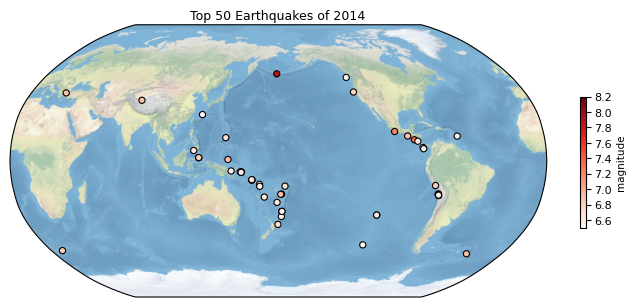

In [9]:
fig = plt.figure(figsize=(6.3, 3.05), dpi=100)
fig.patch.set_alpha(0)
# 这些位置参数用于对齐题目中的示例图
ax = fig.add_axes([.016, .014, .852, .93], projection=ccrs.Robinson(central_longitude=180))
ax.set_global()
ax.stock_img()
sc = ax.scatter(top50.longitude, top50.latitude,
                s=20, c=top50.mag, cmap='Reds', vmin=6.5, vmax=8.2,
                edgecolor='black', linewidth=.8,
                transform=ccrs.PlateCarree(), zorder=5)
fig.text(.441, .976, 'Top 50 Earthquakes of 2014', fontsize=9, ha='center', va='top')
cax = fig.add_axes([.921, .26, .0095, .43])
cb = fig.colorbar(sc, cax=cax)
fig.text(.986, .475, 'magnitude', rotation=90, fontsize=7.5,
         ha='center', va='center')
cb.set_ticks([6.6, 6.8, 7.0, 7.2, 7.4, 7.6, 7.8, 8.0, 8.2])
cb.ax.tick_params(labelsize=8, pad=2)
fig.savefig('PS4_figures/1_earthquakes.png', dpi=100, transparent=True)
plt.show()

In [8]:
#Q2
ds = xr.open_dataset(rain_file)
rain = ds['sat_gauge_precip'].sel(time=slice('2019-01-01', '2019-12-31'))
annual = rain.mean('time')

# 高纬度格点面积较小，计算全球平均时用纬度余弦加权
weights = np.cos(np.deg2rad(annual.lat))
global_mean = float(annual.weighted(weights).mean(('lat', 'lon')))
print('Global mean:', round(global_mean, 2), 'mm/day')

# 两张降水图使用相同的颜色分级
levels = np.arange(0, 13, 1)
cmap = plt.get_cmap('YlGnBu').copy()
cmap.set_over('#182d7e')

Global mean: 3.09 mm/day


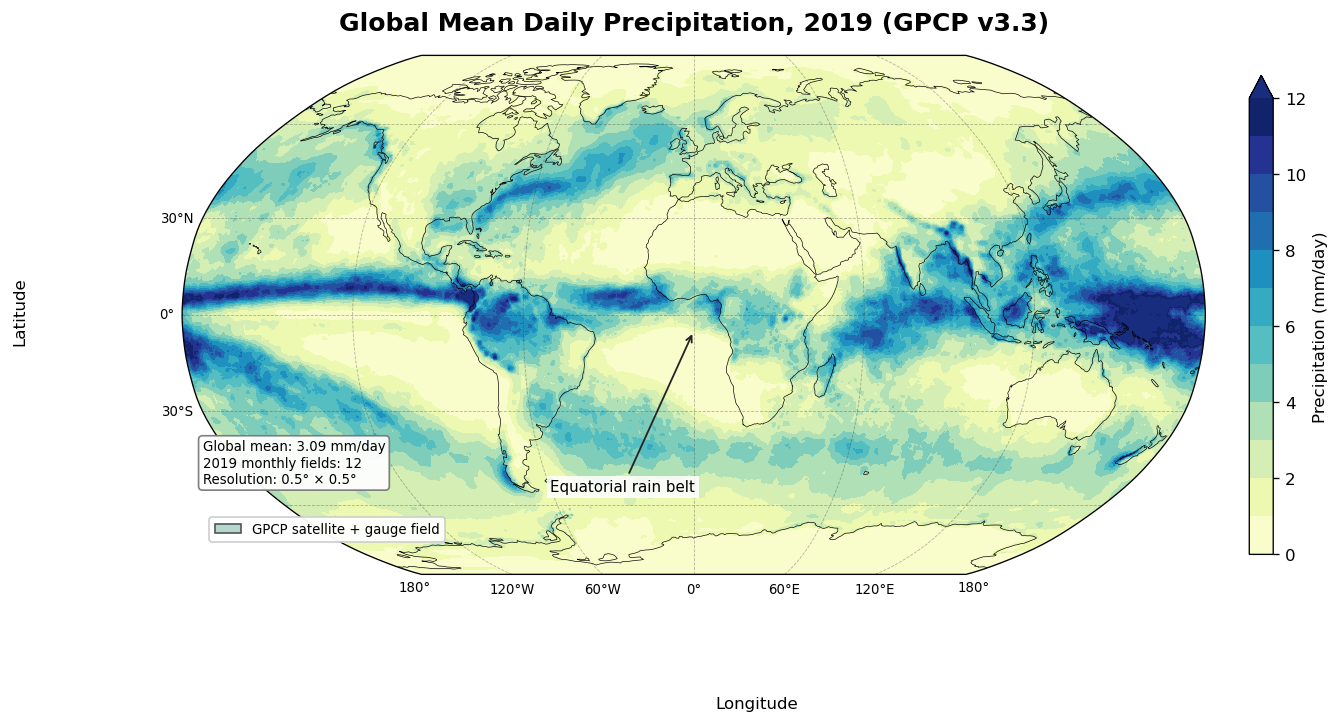

In [11]:
#Q2.1
fig = plt.figure(figsize=(13.5, 7.2))
ax = fig.add_subplot(111, projection=ccrs.Robinson())
ax.set_global()
mesh = ax.contourf(annual.lon, annual.lat, annual, levels=levels, cmap=cmap, extend='max',
                   transform=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale('110m'), facecolor='none', edgecolor='#4e5659', linewidth=.25)
ax.coastlines(resolution='110m', linewidth=.4)
# 经纬网和坐标标签
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels={'bottom':'x','left':'y'},
                  xlocs=np.arange(-180,181,60), ylocs=np.arange(-60,61,30),
                  linewidth=.5, color='#333333', alpha=.35, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size':8}
gl.ylabel_style = {'size':8}
ax.set_title('Global Mean Daily Precipitation, 2019 (GPCP v3.3)', fontsize=15, weight='bold', pad=15)
cb = fig.colorbar(mesh, ax=ax, shrink=.72, pad=.035, ticks=np.arange(0,13,2))
cb.set_label('Precipitation (mm/day)')
ax.legend(handles=[Patch(facecolor='#b6d7cb', edgecolor='#4e5659', label='GPCP satellite + gauge field')],
          loc='lower left', bbox_to_anchor=(.02,.05), framealpha=.95, fontsize=8)
# 箭头指向的地点使用经纬度坐标
ax.annotate('Equatorial rain belt', xy=(0,-5), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(.36,.16), textcoords='axes fraction',
            arrowprops={'arrowstyle':'->','lw':1.1,'color':'#252525'}, fontsize=9,
            bbox={'facecolor':'white','alpha':.86,'edgecolor':'none','pad':2})
# 图内的说明框
ax.text(.02,.17, f'Global mean: {global_mean:.2f} mm/day\n2019 monthly fields: 12\nResolution: 0.5° × 0.5°',
        transform=ax.transAxes, fontsize=8, va='bottom',
        bbox={'boxstyle':'round','facecolor':'white','alpha':.94,'edgecolor':'#777777'})
fig.text(.48,.04,'Longitude',ha='center')
fig.text(.02,.5,'Latitude',va='center',rotation=90)
fig.savefig('PS4_figures/2_global_precip.png', bbox_inches='tight')
plt.show()

In [12]:
#Q2.1
# 纬度从北到南排列
region = annual.sel(lon=slice(100, 135), lat=slice(50, 15))
weights = np.cos(np.deg2rad(region.lat))
region_mean = float(region.weighted(weights).mean(('lat', 'lon')))
print('East Asia mean:', round(region_mean, 2), 'mm/day')

East Asia mean: 3.57 mm/day


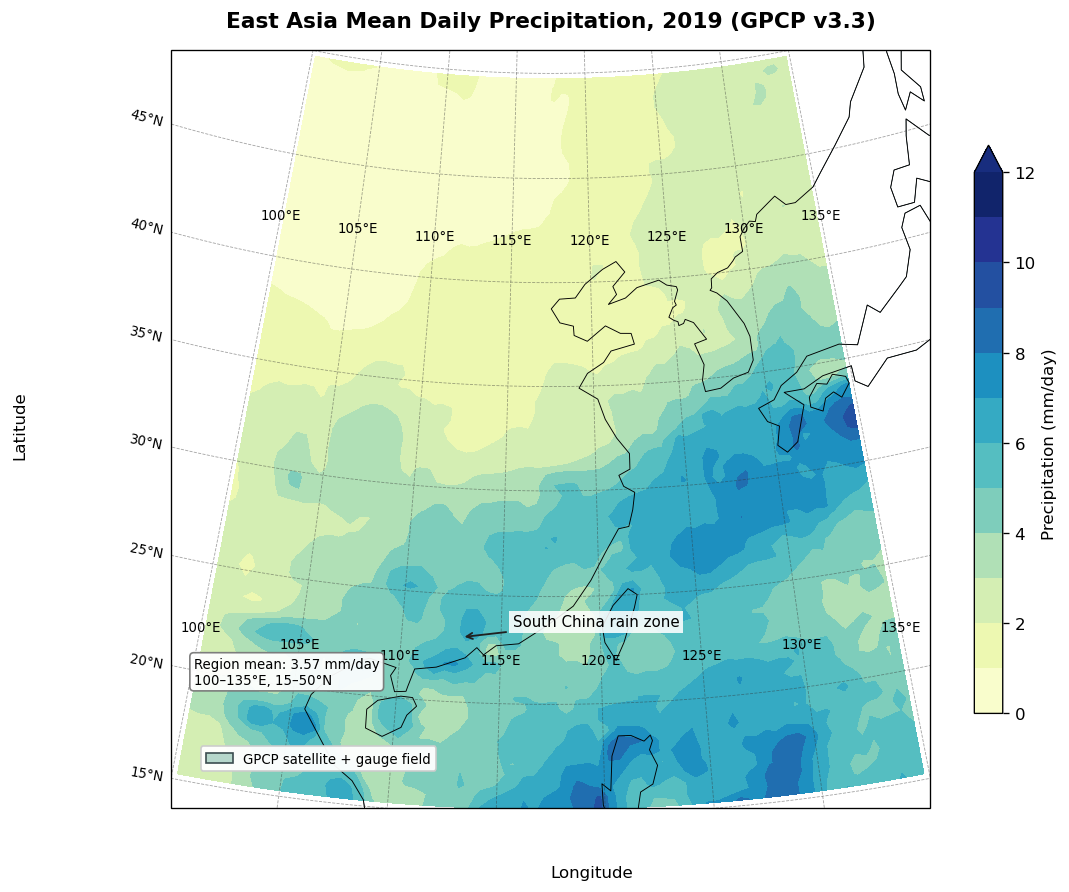

In [13]:
fig = plt.figure(figsize=(10.5, 8.2))
ax = fig.add_subplot(111, projection=ccrs.LambertConformal(central_longitude=117.5, central_latitude=32.5))
ax.set_extent([100,135,15,50], crs=ccrs.PlateCarree())
mesh = ax.contourf(region.lon, region.lat, region,
                   levels=levels, cmap=cmap, extend='max', transform=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale('110m'), facecolor='none', edgecolor='#3c4d50', linewidth=.3)
ax.coastlines(resolution='110m', linewidth=.55)
ax.add_feature(cfeature.OCEAN.with_scale('110m'), facecolor='none', edgecolor='#6a7c83', linewidth=.25)
# 经纬网和坐标标签
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels={'bottom':'x','left':'y'},
                  xlocs=np.arange(100,136,5), ylocs=np.arange(15,51,5),
                  linewidth=.5, color='#333333', alpha=.45, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size':8}
gl.ylabel_style = {'size':8}
ax.set_title('East Asia Mean Daily Precipitation, 2019 (GPCP v3.3)', fontsize=13, weight='bold', pad=14)
cb = fig.colorbar(mesh, ax=ax, shrink=.75, pad=.045, ticks=np.arange(0,13,2))
cb.set_label('Precipitation (mm/day)')
ax.legend(handles=[Patch(facecolor='#b6d7cb', edgecolor='#3c4d50', label='GPCP satellite + gauge field')],
          loc='lower left', bbox_to_anchor=(.03,.04), framealpha=.96, fontsize=8)
# 箭头指向的地点使用经纬度坐标
ax.annotate('South China rain zone', xy=(113,23), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(.45,.24), textcoords='axes fraction',
            arrowprops={'arrowstyle':'->','lw':1.1,'color':'#202020'}, fontsize=9,
            bbox={'facecolor':'white','alpha':.88,'edgecolor':'none','pad':2})
# 图内的说明框
ax.text(.03,.16,f'Region mean: {region_mean:.2f} mm/day\n100–135°E, 15–50°N',
        transform=ax.transAxes, fontsize=8, va='bottom',
        bbox={'boxstyle':'round','facecolor':'white','alpha':.94,'edgecolor':'#777777'})
fig.text(.48,.04,'Longitude',ha='center')
fig.text(.02,.5,'Latitude',va='center',rotation=90)
fig.savefig('PS4_figures/3_east_asia_precip.png', bbox_inches='tight')
plt.show()